# Assignment 6: Soft Clustering – Fuzzy C-means and Gaussian Mixture Models

## Introduction
In this assignment I apply two soft clustering methods, Fuzzy C-means (FCM) and Gaussian Mixture Models (GMM), to the Bank Marketing dataset from the UCI Machine Learning Repository (Moro, Cortez & Rita, 2014). It contains clients of a Portuguese bank who were contacted in phone marketing campaigns, with numeric features (like age and balance) and categorical features (like job and education). The label y says whether the client subscribed to a term deposit. I do not use y to build the clusters, only to evaluate them.

Unlike K-means, soft clustering does not put each client into just one cluster. FCM gives each client a membership value for every cluster, and GMM gives each client a probability for every cluster.

My steps:
- Explain hard vs soft clustering (Task 1)
- Load and preprocess the data, and reduce it with PCA
- Implement Fuzzy C-means and discuss membership values (Task 2)
- Implement GMM and discuss probability vectors (Task 3)
- Compare both models with evaluation metrics (Task 4)
- Use AIC and BIC to choose the number of GMM components (Task 5)
- Apply a Bayesian GMM and discuss component selection (Task 6)

Note: Fuzzy C-means is not part of scikit-learn, so I implemented it myself with NumPy, following the formulas from Lesson 6. Because GMM assumes Gaussian features and most of the bank features are one-hot (0/1), I used PCA to convert the preprocessed data into continuous components before fitting both models.

## Task 1 – Hard Clustering vs Soft Clustering

### Hard clustering
- Each data point belongs to exactly one cluster.
- The result is a single label per point (for example, client 25 is in cluster 2).
- Examples: K-means, K-medoids, DBSCAN, Agglomerative Clustering.
- Points on the border between two clusters are forced into one of them, even if they are almost equally close to both.

### Soft clustering
- Each data point belongs to every cluster with a certain degree.
- The result is a vector of values per point that adds up to 1 (for example, client 25 is 0.70 in cluster 2, 0.25 in cluster 0 and 0.05 in cluster 1).
- There are two main types:
  - Fuzzy clustering (Fuzzy C-means): the values are membership degrees based on how close a point is to each cluster centre.
  - Probabilistic clustering (Gaussian Mixture Models): the values are probabilities that the point was generated by each cluster, based on distance, cluster size and cluster shape.
- A hard label can still be taken from a soft result by choosing the cluster with the highest value.

### Simple example
A shopper who buys groceries, headphones and clothes. K-means would put them only in the "grocery family" segment. Fuzzy C-means might say 59% grocery, 27% fashion and 14% tech. A GMM might say 84% grocery, 14% fashion and 2% tech, because it also considers that grocery shoppers are the most common type.

### When soft clustering is preferred
- Customer segmentation with mixed behaviour: a customer can be partly a bargain hunter and partly a premium buyer, so marketing can combine offers instead of choosing only one.
- Overlapping groups: when clusters overlap (like the bank clients in Assignment 2, with a silhouette score of only 0.16), soft clustering shows which clients are truly in between segments.
- Medical imaging: pixels on the border between two tissues can belong partly to both.
- Document topics: an article can be 70% sports and 30% business.
- Risk scoring: a bank may want to know how likely a client is to belong to a high-risk group, not just a yes/no label.

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture, BayesianGaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score, homogeneity_score, completeness_score
from scipy.spatial.distance import cdist

np.random.seed(42)
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## 2. Load and Preprocess the Data

Shape: (4521, 17)
After encoding and scaling: (4521, 30)
   2 components keep 35.8% of the variance
   5 components keep 71.2% of the variance
   8 components keep 83.3% of the variance
  10 components keep 87.6% of the variance
  12 components keep 91.2% of the variance
  15 components keep 95.0% of the variance


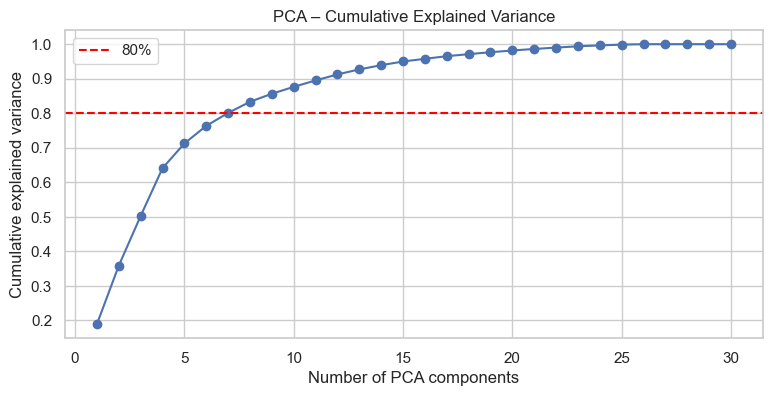

In [2]:
bank_df = pd.read_csv("bank.csv", sep=";")
print("Shape:", bank_df.shape)

y_true = (bank_df["y"] == "yes").astype(int)
clean_df = bank_df.drop(columns=["day", "month", "duration", "contact", "pdays", "y"]).copy()
clean_df["poutcome"] = clean_df["poutcome"].replace("unknown", "not_contacted")

num_features = ["age", "balance", "campaign", "previous"]
cat_features = ["job", "marital", "education", "default", "housing", "loan", "poutcome"]

X = clean_df.copy()
X["balance"] = np.sign(X["balance"]) * np.log1p(np.abs(X["balance"]))
X["campaign"] = np.log1p(X["campaign"])
X["previous"] = np.log1p(X["previous"])

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(drop="if_binary", sparse_output=False), cat_features),
])
X_prep = preprocessor.fit_transform(X)
print("After encoding and scaling:", X_prep.shape)

pca_full = PCA(random_state=42).fit(X_prep)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
for n in [2, 5, 8, 10, 12, 15]:
    print(f"  {n:2d} components keep {cum_var[n-1]*100:.1f}% of the variance")

plt.figure(figsize=(9, 4))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker="o")
plt.axhline(0.8, color="red", linestyle="--", label="80%")
plt.xlabel("Number of PCA components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA – Cumulative Explained Variance")
plt.legend()
plt.show()

### Interpretation – Preprocessing and PCA
- The dataset has 4,521 clients and 17 columns. After the same cleaning and preprocessing as Assignment 2 (dropping campaign-call columns, log-transforming skewed features, scaling numeric columns and one-hot encoding categorical columns), I have 30 columns.
- Most of these columns are one-hot 0/1 values, which are not bell-shaped. Since a GMM assumes Gaussian (bell-shaped) features, I used PCA to turn them into continuous components.
- The first PCA component alone keeps about 19% of the variance, 2 components keep 35.8%, and 5 components keep 71.2%. The curve crosses 80% at 7 components and becomes very flat after about 10 components, so the last components add very little information.
- I chose 8 components, which keep 83.3% of the variance. This keeps most of the information while reducing the data from 30 to 8 dimensions, which makes it easier for FCM and GMM to find clusters.

## 3. Fuzzy C-means (Task 2) then ### 3.1 Fuzzy C-means Function and Choosing the Number of Clusters

In [3]:
pca = PCA(n_components=8, random_state=42)
X_pca = pca.fit_transform(X_prep)
print("PCA data:", X_pca.shape, "| Variance kept:", round(pca.explained_variance_ratio_.sum() * 100, 1), "%")


PCA data: (4521, 8) | Variance kept: 83.3 %


In [4]:
def fuzzy_cmeans(X, c, m=2.0, max_iter=300, tol=1e-5, seed=42):
    rng = np.random.default_rng(seed)
    W = rng.random((X.shape[0], c))
    W = W / W.sum(axis=1, keepdims=True)
    for iteration in range(1, max_iter + 1):
        Wm = W ** m
        centers = (Wm.T @ X) / Wm.sum(axis=0)[:, None]
        d = cdist(X, centers) + 1e-10
        W_new = 1.0 / ((d[:, :, None] / d[:, None, :]) ** (2.0 / (m - 1.0))).sum(axis=2)
        if np.abs(W_new - W).max() < tol:
            W = W_new
            break
        W = W_new
    pc = np.mean(np.sum(W ** 2, axis=1))
    pc_norm = (c * pc - 1) / (c - 1)
    return centers, W, pc_norm, iteration

In [5]:
fcm_rows = []
for c in range(2, 9):
    centers, W, pc_norm, n_iter = fuzzy_cmeans(X_pca, c=c, m=1.5)
    labels = W.argmax(axis=1)
    fcm_rows.append({"c": c, "iterations": n_iter,
                     "normalized_PC": round(pc_norm, 4),
                     "silhouette": round(silhouette_score(X_pca, labels), 4)})
fcm_table = pd.DataFrame(fcm_rows)
print(fcm_table.to_string(index=False))

 c  iterations  normalized_PC  silhouette
 2          53         0.1676      0.1430
 3         159         0.2058      0.1572
 4         102         0.3945      0.1943
 5         100         0.3960      0.2000
 6         129         0.3579      0.1644
 7         133         0.3361      0.1702
 8         193         0.3032      0.1536


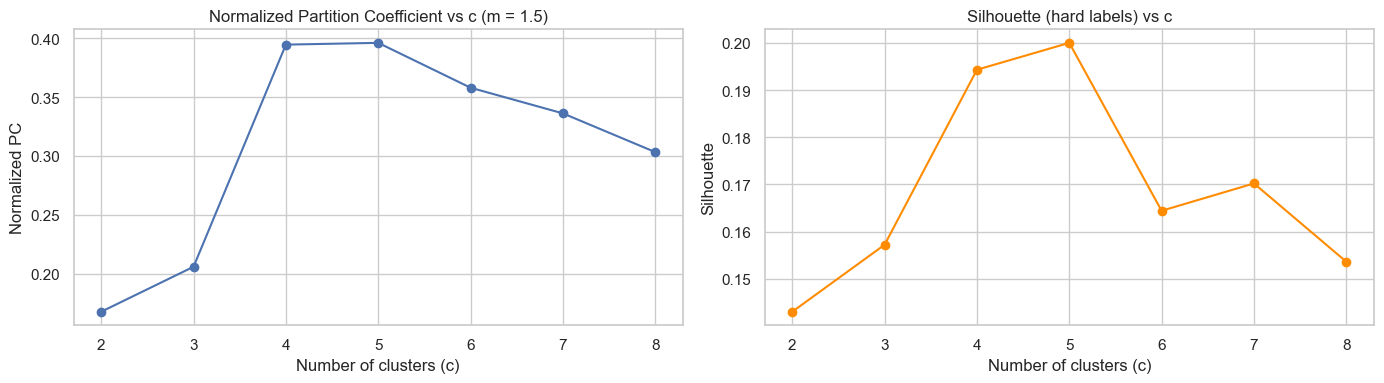

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(fcm_table["c"], fcm_table["normalized_PC"], marker="o")
axes[0].set_title("Normalized Partition Coefficient vs c (m = 1.5)")
axes[0].set_xlabel("Number of clusters (c)"); axes[0].set_ylabel("Normalized PC")
axes[1].plot(fcm_table["c"], fcm_table["silhouette"], marker="o", color="darkorange")
axes[1].set_title("Silhouette (hard labels) vs c")
axes[1].set_xlabel("Number of clusters (c)"); axes[1].set_ylabel("Silhouette")
plt.tight_layout(); plt.show()

### Interpretation – Choosing the Number of FCM Clusters
- I reduced the data to 8 PCA components (83.3% of the variance) and wrote Fuzzy C-means myself using the Lesson 6 formulas: the centroids are weighted means of all clients, and each client's membership depends on how close it is to each centroid compared with the others. I used m = 1.5 for a moderate level of fuzziness.
- I tested 2 to 8 clusters and measured two things: the normalized Partition Coefficient (PC), which goes from 0 (completely fuzzy) to 1 (hard, crisp clusters), and the silhouette score of the hard labels (the cluster with the highest membership).
- c = 5 is the best on both measures, with the highest normalized PC (0.396) and the highest silhouette score (0.200). This also matches the 5 segments I found with K-means on the same data in Assignment 2.
- With only 2 or 3 clusters, the normalized PC is very low (0.168 and 0.206), so clients are split almost evenly between clusters. With more than 5 clusters, the PC and silhouette drop again, so the extra clusters are not well separated.
- Even at c = 5, the normalized PC is only about 0.40, which means the clusters are quite fuzzy and many clients belong partly to more than one cluster. This makes sense because the bank clients overlap a lot, which is exactly the situation where soft clustering is useful.
- The algorithm needed between 53 and 193 iterations to converge, and more clusters generally took longer.

### 3.2 Effect of the Fuzziness Parameter m

In [7]:
m_rows = []
for m in [1.1, 1.3, 1.5, 2.0, 2.5]:
    _, W_m, pc_m, it_m = fuzzy_cmeans(X_pca, c=5, m=m)
    max_mem = W_m.max(axis=1)
    m_rows.append({"m": m, "iterations": it_m,
                   "normalized_PC": round(pc_m, 4),
                   "avg_highest_membership": round(max_mem.mean(), 4),
                   "%_clients_below_0.6": round((max_mem < 0.6).mean() * 100, 1),
                   "silhouette": round(silhouette_score(X_pca, W_m.argmax(axis=1)), 4)})
print(pd.DataFrame(m_rows).to_string(index=False))

  m  iterations  normalized_PC  avg_highest_membership  %_clients_below_0.6  silhouette
1.1          45         0.9241                  0.9582                  2.6      0.2084
1.3          41         0.6941                  0.8341                 12.8      0.2057
1.5         100         0.3960                  0.6600                 37.5      0.2000
2.0          30         0.0000                  0.2000                100.0      0.0983
2.5          17         0.0000                  0.2000                100.0     -0.0268


### 3.3 Final Fuzzy C-means Model and Membership Values

In [8]:
fcm_centers, W_fcm, fcm_pc, _ = fuzzy_cmeans(X_pca, c=5, m=1.5)
fcm_labels = W_fcm.argmax(axis=1)
fcm_max = W_fcm.max(axis=1)

profile_df = clean_df.copy()
profile_df["fcm_cluster"] = fcm_labels
profile_df["fcm_max_membership"] = fcm_max
print("FCM cluster sizes (hard labels):", np.bincount(fcm_labels).tolist())
display(profile_df.groupby("fcm_cluster").agg(
    size=("age", "size"),
    age_mean=("age", "mean"),
    balance_median=("balance", "median"),
    campaign_mean=("campaign", "mean"),
    previous_mean=("previous", "mean"),
    contacted_before_pct=("poutcome", lambda s: round((s != "not_contacted").mean() * 100, 1)),
    avg_max_membership=("fcm_max_membership", "mean"),
).round(2))

mem_df = pd.DataFrame(W_fcm.round(3), columns=[f"cluster_{j}" for j in range(5)])
examples = [np.argmax(fcm_max), np.argmin(fcm_max), int(np.argsort(fcm_max)[len(fcm_max) // 2])]
print("\nMembership examples (most certain, most uncertain, typical client):")
display(mem_df.iloc[examples].assign(client=examples).set_index("client"))

FCM cluster sizes (hard labels): [1084, 674, 587, 811, 1365]


,size,age_mean,balance_median,campaign_mean,previous_mean,contacted_before_pct,avg_max_membership
fcm_cluster,,,,,,,
0,1084,53.35,744.5,1.88,0.06,5.4,0.66
1,674,40.17,683.5,1.93,3.38,100.0,0.68
2,587,38.99,-46.0,2.26,0.11,7.3,0.68
3,811,40.31,430.0,7.07,0.03,2.5,0.61
4,1365,33.44,622.0,1.63,0.02,1.5,0.67



Membership examples (most certain, most uncertain, typical client):


,cluster_0,cluster_1,cluster_2,cluster_3,cluster_4
client,,,,,
765,0.004,0.984,0.003,0.004,0.005
1912,0.276,0.252,0.282,0.080,0.110
1936,0.155,0.038,0.048,0.086,0.672


### Interpretation – Final Fuzzy C-means Model (c = 5, m = 1.5)
Using each client's highest membership as a hard label, FCM found five segments that closely match the five K-means segments from Assignment 2:
- Cluster 4 – Young new prospects (1,365 clients): the youngest group (average age 33.4), almost never contacted before (1.5%).
- Cluster 0 – Older settled savers (1,084 clients): the oldest group (average age 53.4) with the highest median balance (€744.50).
- Cluster 3 – Heavily chased (811 clients): about 7.07 calls in this campaign, far more than the other groups.
- Cluster 1 – Past-campaign contacts (674 clients): 100% were contacted before, with about 3.38 previous contacts on average.
- Cluster 2 – Financially stretched borrowers (587 clients): median balance of -€46, so at least half are overdrawn.

Finding the same segments with a different method suggests these groups are real.

In [10]:
from matplotlib.lines import Line2D

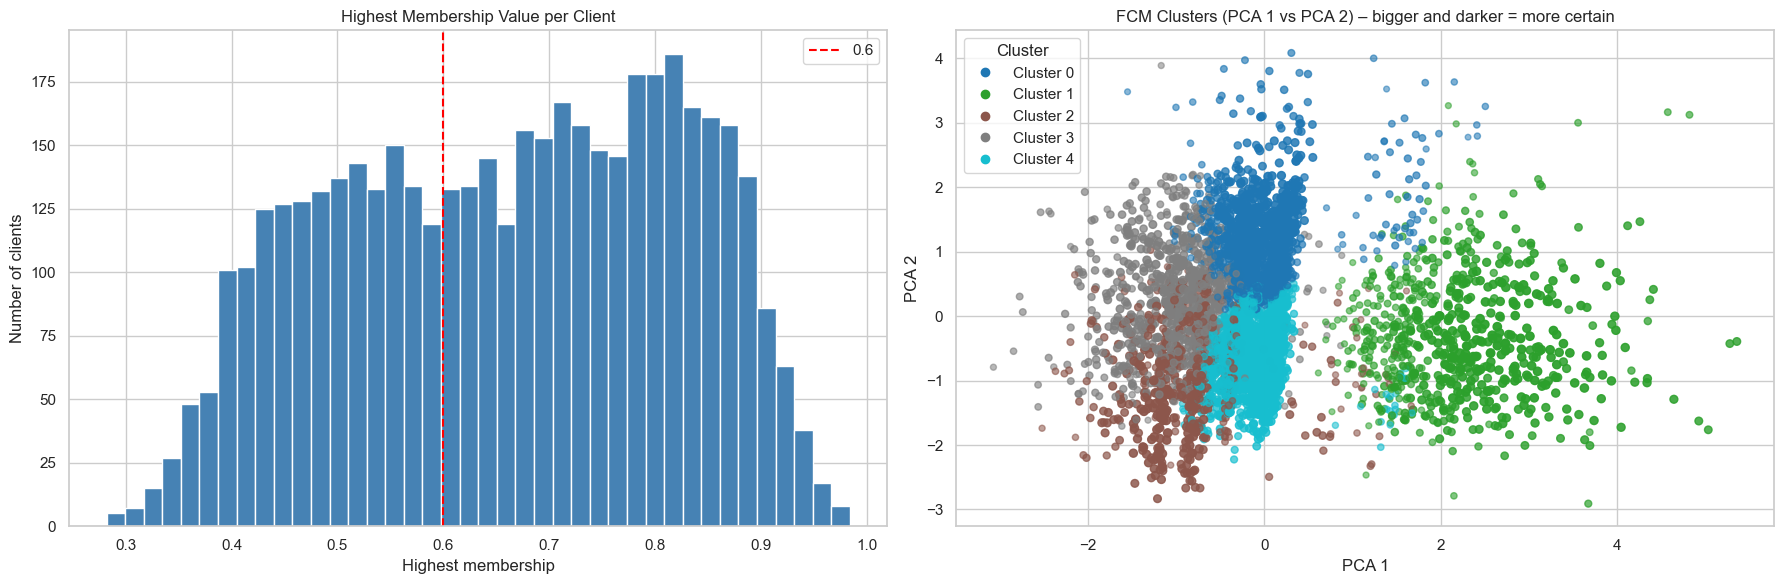

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
axes[0].hist(fcm_max, bins=40, color="steelblue")
axes[0].axvline(0.6, color="red", linestyle="--", label="0.6")
axes[0].set_title("Highest Membership Value per Client")
axes[0].set_xlabel("Highest membership"); axes[0].set_ylabel("Number of clients"); axes[0].legend()

sc = axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=fcm_labels, cmap="tab10", s=8 + 30 * fcm_max, alpha=0.3 + 0.7 * fcm_max)
axes[1].set_title("FCM Clusters (PCA 1 vs PCA 2) – bigger and darker = more certain")
axes[1].set_xlabel("PCA 1"); axes[1].set_ylabel("PCA 2")
handles = [Line2D([0], [0], marker="o", linestyle="", color=sc.cmap(sc.norm(j)), label=f"Cluster {j}")
           for j in range(5)]
axes[1].legend(handles=handles, title="Cluster")
plt.tight_layout(); plt.show()


### Interpretation – Membership Values
- Each client has 5 membership values that add up to 1. The average highest membership in each cluster is only between 0.61 and 0.68, so a typical client belongs about two-thirds to their main segment and one-third to the others. The heavily chased cluster is the fuzziest (0.61).
- The histogram shows highest memberships from about 0.29 to 0.98. ____% of clients have a highest membership below 0.6 [add from the m table, m = 1.5 row], so many clients are truly between segments.
- Client 765 is the most certain: 98.4% in cluster 1 (past-campaign contacts) and almost 0 everywhere else.
- Client 1912 is the most uncertain: 27.6% in cluster 0, 25.2% in cluster 1 and 28.2% in cluster 2. This client is almost equally an older saver, a past contact and a stretched borrower. K-means would force them into one segment based on a tiny difference, while FCM shows they are truly mixed.
- Client 1936 is a typical client: 67.2% in cluster 4 (young new prospects), with 15.5% in cluster 0 (older savers), so mostly a young prospect with some older-saver traits.
- In the PCA plot, the past-campaign contacts (cluster 1) are clearly separated on the right, while the other four clusters overlap on the left. Clients in the overlapping areas are drawn smaller and lighter because their memberships are lower.
- For marketing, these memberships are useful: a bank could target clients with a high membership in one segment with a focused offer, and give mixed clients like client 1912 a combination of offers.

## 4. Gaussian Mixture Model (Task 3)

In [12]:
gmm = GaussianMixture(n_components=5, covariance_type="full", n_init=5, random_state=42)
gmm.fit(X_pca)
P_gmm = gmm.predict_proba(X_pca)
gmm_labels = P_gmm.argmax(axis=1)
gmm_max = P_gmm.max(axis=1)

print("Converged:", gmm.converged_, "| Iterations:", gmm.n_iter_)
print("Component weights:", gmm.weights_.round(3))
print("GMM cluster sizes (hard labels):", np.bincount(gmm_labels).tolist())

Converged: True | Iterations: 41
Component weights: [0.355 0.087 0.181 0.229 0.148]
GMM cluster sizes (hard labels): [1611, 345, 816, 1079, 670]


In [13]:
profile_df["gmm_cluster"] = gmm_labels
profile_df["gmm_max_prob"] = gmm_max
display(profile_df.groupby("gmm_cluster").agg(
    size=("age", "size"),
    age_mean=("age", "mean"),
    balance_median=("balance", "median"),
    campaign_mean=("campaign", "mean"),
    previous_mean=("previous", "mean"),
    contacted_before_pct=("poutcome", lambda s: round((s != "not_contacted").mean() * 100, 1)),
    avg_max_prob=("gmm_max_prob", "mean"),
).round(2))

prob_df = pd.DataFrame(P_gmm.round(3), columns=[f"comp_{j}" for j in range(5)])
gmm_examples = [765, 1912, 1936, int(np.argmin(gmm_max))]
print("\nProbability vectors (same 3 clients as FCM + GMM's most uncertain client):")
display(prob_df.iloc[gmm_examples].assign(client=gmm_examples).set_index("client"))
print(f"Clients with highest probability below 0.6: {(gmm_max < 0.6).mean() * 100:.1f}%")

print("\nFCM vs GMM (rows = FCM cluster, columns = GMM component):")
display(pd.crosstab(fcm_labels, gmm_labels))

,size,age_mean,balance_median,campaign_mean,previous_mean,contacted_before_pct,avg_max_prob
gmm_cluster,,,,,,,
0,1611,43.66,378.0,3.00,0.00,0.0,1.00
1,345,40.82,416.0,2.81,0.00,0.0,0.98
2,816,41.56,631.5,2.02,3.01,100.0,1.00
3,1079,37.84,790.0,2.97,0.00,0.0,0.94
4,670,40.24,16.0,2.96,0.00,0.0,0.91



Probability vectors (same 3 clients as FCM + GMM's most uncertain client):


,comp_0,comp_1,comp_2,comp_3,comp_4
client,,,,,
765,0.0,0.000,1.0,0.000,0.000
1912,0.0,0.000,1.0,0.000,0.000
1936,0.0,0.000,0.0,0.983,0.017
2985,0.0,0.373,0.0,0.393,0.234


Clients with highest probability below 0.6: 1.5%

FCM vs GMM (rows = FCM cluster, columns = GMM component):


col_0,0,1,2,3,4
row_0,,,,,
0,598,105,58,196,127
1,0,0,674,0,0
2,240,59,43,0,245
3,344,50,20,276,121
4,429,131,21,607,177


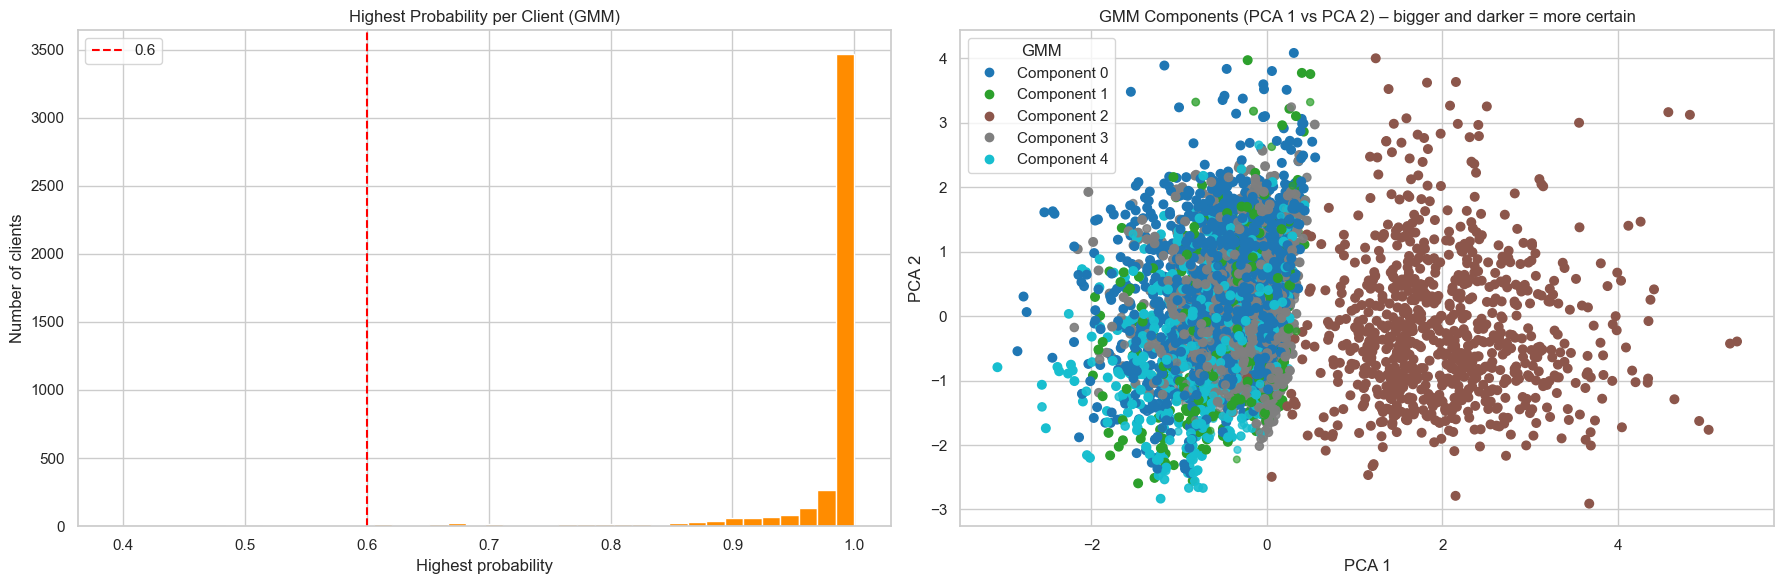

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
axes[0].hist(gmm_max, bins=40, color="darkorange")
axes[0].axvline(0.6, color="red", linestyle="--", label="0.6")
axes[0].set_title("Highest Probability per Client (GMM)")
axes[0].set_xlabel("Highest probability"); axes[0].set_ylabel("Number of clients"); axes[0].legend()

sc2 = axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=gmm_labels, cmap="tab10", s=8 + 30 * gmm_max, alpha=0.3 + 0.7 * gmm_max)
handles2 = [Line2D([0], [0], marker="o", linestyle="", color=sc2.cmap(sc2.norm(j)), label=f"Component {j}")
            for j in range(5)]
axes[1].legend(handles=handles2, title="GMM")
axes[1].set_title("GMM Components (PCA 1 vs PCA 2) – bigger and darker = more certain")
axes[1].set_xlabel("PCA 1"); axes[1].set_ylabel("PCA 2")
plt.tight_layout(); plt.show()

### 4.1 What Separates the GMM Components?

In [15]:
cat_profile = profile_df.groupby("gmm_cluster").agg(
    top_job=("job", lambda s: s.value_counts().index[0]),
    top_job_pct=("job", lambda s: round(s.value_counts(normalize=True).iloc[0] * 100, 1)),
    top_marital=("marital", lambda s: s.value_counts().index[0]),
    top_education=("education", lambda s: s.value_counts().index[0]),
    top_education_pct=("education", lambda s: round(s.value_counts(normalize=True).iloc[0] * 100, 1)),
    housing_yes_pct=("housing", lambda s: round((s == "yes").mean() * 100, 1)),
    loan_yes_pct=("loan", lambda s: round((s == "yes").mean() * 100, 1)),
)
display(cat_profile)

,top_job,top_job_pct,top_marital,top_education,top_education_pct,housing_yes_pct,loan_yes_pct
gmm_cluster,,,,,,,
0,blue-collar,35.7,married,secondary,69.0,60.2,18.1
1,blue-collar,63.5,single,primary,45.5,56.8,14.2
2,management,22.8,married,secondary,50.9,63.2,12.1
3,management,48.5,married,tertiary,71.5,48.1,10.3
4,management,34.0,divorced,secondary,54.0,53.4,21.0


### Interpretation – Gaussian Mixture Model (5 components)
- The GMM converged after 41 EM iterations. The component weights (0.355, 0.087, 0.181, 0.229 and 0.148) show how common each group is, so unlike FCM, GMM also learns the size of each segment.
- The GMM gives each client a probability vector of 5 values that add up to 1. These probabilities are very confident: the average highest probability is between 0.91 and 1.00 in every component, and only 1.5% of clients have a highest probability below 0.6. The histogram is almost entirely at 1.0.
- Client 765 is 100% in component 2, which agrees with FCM (98.4%). Client 1912, who was almost equally split across three FCM clusters, is 100% in component 2 in the GMM. Client 1936 is 98.3% in component 3. The most uncertain GMM client is client 2985, with 37.3% in component 1, 39.3% in component 3 and 23.4% in component 4.
- Only one segment matches FCM: component 2 (816 clients) contains all 674 clients of FCM's past-campaign contacts cluster, and 100% of its clients were contacted before. The other four components do not line up with the FCM clusters. For example, FCM's young new prospects are split between GMM components 3 and 0.
- In the PCA plot, component 2 is clearly separated on the right, while the other four components are mixed together on the left.

## 5. Comparing FCM and GMM (Task 4)

In [18]:
def soft_metrics(P, labels):
    c = P.shape[1]
    pc = np.mean(np.sum(P ** 2, axis=1))
    return {"silhouette": silhouette_score(X_pca, labels),
            "ARI_vs_y": adjusted_rand_score(y_true, labels),
            "homogeneity_vs_y": homogeneity_score(y_true, labels),
            "completeness_vs_y": completeness_score(y_true, labels),
            "normalized_PC": (c * pc - 1) / (c - 1),
            "avg_highest_value": P.max(axis=1).mean(),
            "%_below_0.6": (P.max(axis=1) < 0.6).mean() * 100}

comparison = pd.DataFrame({"Fuzzy C-means": soft_metrics(W_fcm, fcm_labels),
                           "GMM": soft_metrics(P_gmm, gmm_labels)}).round(4)
display(comparison)



,Fuzzy C-means,GMM
silhouette,0.2000,0.0947
ARI_vs_y,0.0046,0.0199
homogeneity_vs_y,0.0295,0.0403
completeness_vs_y,0.0068,0.0096
normalized_PC,0.3960,0.9391
avg_highest_value,0.6600,0.9684
%_below_0.6,37.5359,1.5262


### Interpretation – What Separates the GMM Components
- GMM components 0, 1, 3 and 4 have very similar numeric profiles (about 3 calls, no previous contacts and similar ages), so the GMM did not split clients by age, balance or calls like FCM did.
- Instead, they differ by their categories:
  - Component 1 (345 clients): mostly single, with primary education, and 63.5% blue-collar. Young single workers.
  - Component 3 (1,079 clients): mostly management (48.5%), married, and 71.5% with tertiary education. Educated professionals.
  - Component 4 (670 clients): mostly divorced, with the lowest median balance (€16) and the most personal loans (21%).
  - Component 0 (1,611 clients): mostly blue-collar, married, with secondary education. Married working families.
  - Component 2 (816 clients): past-campaign contacts.
- Most of the 8 PCA components come from one-hot category columns, which create stacks of clients with exactly the same category combinations. With a full covariance matrix, each Gaussian can become very narrow and fit tightly around these stacks, which is why the GMM gives such confident probabilities. So the GMM finds demographic segments, while FCM finds behaviour and financial segments.

In [17]:
rate_table = pd.DataFrame({
    "FCM subscribe %": profile_df.assign(y=y_true).groupby("fcm_cluster")["y"].mean().mul(100).round(1),
    "GMM subscribe %": profile_df.assign(y=y_true).groupby("gmm_cluster")["y"].mean().mul(100).round(1)})
print("Overall subscribe rate:", round(y_true.mean() * 100, 1), "%")
display(rate_table)

Overall subscribe rate: 11.5 %


,FCM subscribe %,GMM subscribe %
0,11.7,6.6
1,22.4,14.5
2,6.3,22.5
3,7.9,11.0
4,10.4,9.3


## Task 4 – Comparing Fuzzy C-means and GMM
- Cluster separation: FCM has a higher silhouette score (0.200 vs 0.095), so its clusters are tighter and better separated in distance. This is expected because both FCM and the silhouette score are based on distances, while the GMM is based on probabilities and covariance shapes.
- Agreement with the subscription label: both models have ARI and homogeneity scores close to 0 (ARI 0.005 for FCM and 0.020 for GMM), so neither clustering matches the yes/no outcome. The segments describe types of clients, not whether they will subscribe. The GMM is slightly better on these label-based scores.
- Fuzziness: FCM is very fuzzy (normalized PC 0.396, and 37.5% of clients have a highest membership below 0.6), while the GMM is almost hard (normalized PC 0.939, only 1.5% below 0.6). FCM shows many in-between clients, while the GMM is very sure about almost everyone.
- Type of segments: FCM found behaviour and financial segments (young prospects, older savers, heavily chased, past contacts and stretched borrowers). The GMM found demographic segments based on job, marital status and education. Both found the past-campaign contacts as a clear, separate group.
- Business value: in both models, past-campaign contacts subscribed at about 22%, about twice the overall rate of 11.5%. FCM showed that heavily chased clients (7.9%) and stretched borrowers (6.3%) subscribe the least. The GMM added a new insight: young single workers subscribe more than average (14.5%), while married blue-collar families subscribe the least (6.6%).
- Overall, FCM gives clearer, better-separated segments and more honest memberships for this overlapping data. The GMM is more flexible (it learns cluster sizes and shapes), but on this mostly categorical data it becomes overconfident by fitting tightly around category combinations.

## 6. Choosing the Number of GMM Components with AIC and BIC (Task 5)

In [19]:
n_range = range(1, 13)
ic_rows = []
for cov in ["full", "diag", "spherical"]:
    for n in n_range:
        gm = GaussianMixture(n_components=n, covariance_type=cov, n_init=3, random_state=42).fit(X_pca)
        ic_rows.append({"covariance": cov, "n_components": n,
                        "AIC": gm.aic(X_pca), "BIC": gm.bic(X_pca),
                        "log_likelihood": gm.score(X_pca) * len(X_pca)})
ic_df = pd.DataFrame(ic_rows)

best = ic_df.loc[ic_df.groupby("covariance")["BIC"].idxmin()]
print("Best number of components by BIC for each covariance type:")
print(best.round(1).to_string(index=False))
print("\nFull covariance results:")
print(ic_df[ic_df["covariance"] == "full"].round(1).to_string(index=False))

Best number of components by BIC for each covariance type:
covariance  n_components     AIC     BIC  log_likelihood
      diag            12 63468.3 64770.8        -31531.1
      full            12  9218.3 12676.8         -4070.1
 spherical            12 73019.1 73782.7        -36390.6

Full covariance results:
covariance  n_components     AIC     BIC  log_likelihood
      full             1 82623.4 82905.7        -41267.7
      full             2 51382.6 51953.7        -25602.3
      full             3 45809.8 46669.6        -22770.9
      full             4 42105.2 43253.8        -20873.6
      full             5 32614.6 34051.9        -16083.3
      full             6 29552.5 31278.5        -14507.2
      full             7 17911.1 19925.9         -8641.6
      full             8 19222.2 21525.7         -9252.1
      full             9 18292.3 20884.6         -8742.2
      full            10 15068.0 17949.0         -7085.0
      full            11 11511.2 14680.9         -5261.6
   

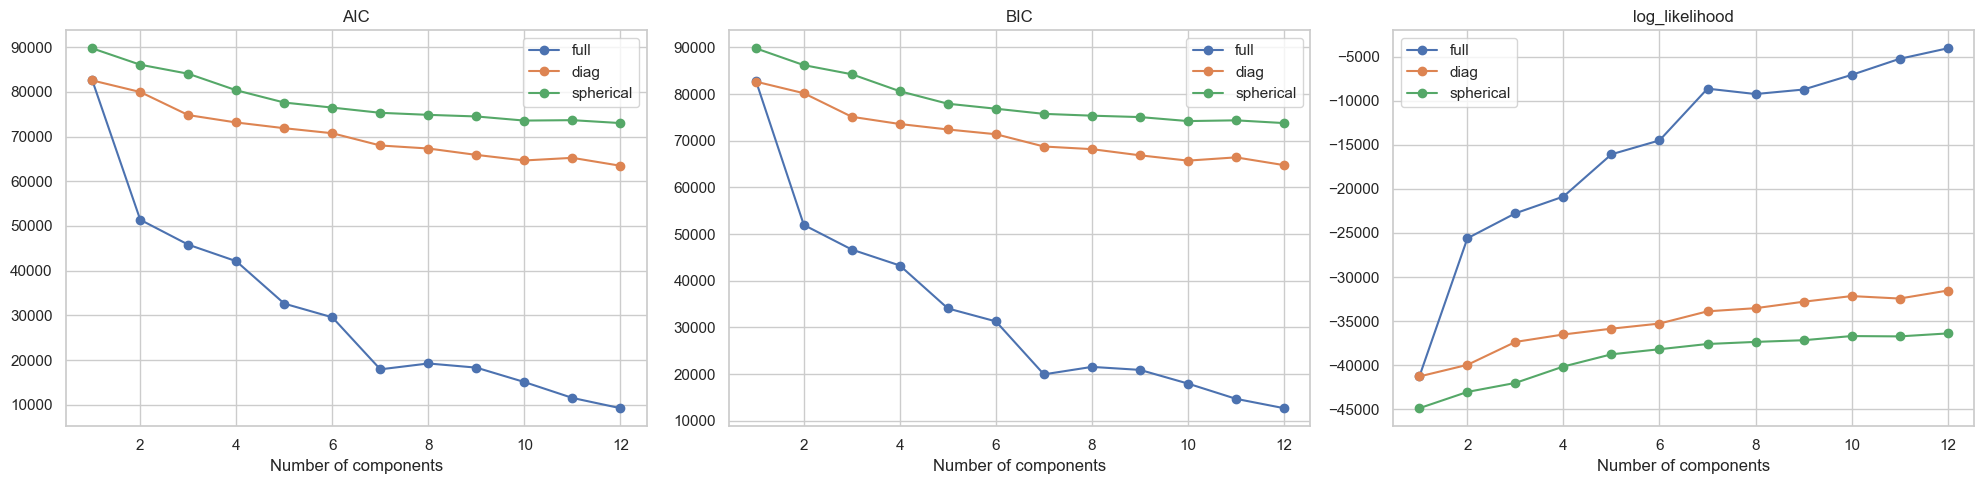

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, metric in zip(axes, ["AIC", "BIC", "log_likelihood"]):
    for cov in ["full", "diag", "spherical"]:
        sub = ic_df[ic_df["covariance"] == cov]
        ax.plot(sub["n_components"], sub[metric], marker="o", label=cov)
    ax.set_title(metric); ax.set_xlabel("Number of components"); ax.legend()
plt.tight_layout(); plt.show()

## Task 5 – AIC and BIC for Choosing the Number of Components

### What AIC and BIC do
- The log-likelihood measures how well a GMM fits the data, but it always improves when more components are added, so on its own it would always choose the biggest model (overfitting).
- AIC (Akaike Information Criterion) = 2 × number of parameters − 2 × log-likelihood.
- BIC (Bayesian Information Criterion) = number of parameters × log(number of samples) − 2 × log-likelihood. BIC penalizes extra parameters more strongly than AIC, so it prefers simpler models.
- For both, lower is better. The best model is the one with the lowest value, where adding more components no longer improves the fit enough to justify the extra parameters.

### My results
- I tested 1 to 12 components with three covariance types (full, diagonal and spherical).
- Full covariance is by far the best type: at 12 components its BIC is 12,677, compared with 64,771 for diagonal and 73,783 for spherical. Full covariance allows tilted, stretched clusters, which fit this data much better.
- For all three covariance types, AIC and BIC kept decreasing up to 12 components, so there is no clear minimum in the range I tested.
- For full covariance, there is a local minimum at 7 components (BIC 19,926). The BIC then rises at 8 and 9 components (21,526 and 20,885) before falling again from 10 to 12.
- The log-likelihood also dropped at 8 components (-9,252 vs -8,642 at 7), even though more components should fit at least as well. This means the EM algorithm got stuck in a worse local solution at 8 components.

### Why AIC and BIC do not find a clear answer here
- Most of my PCA components come from one-hot (0/1) category columns, so many clients have exactly the same values. With full covariance, a Gaussian component can collapse almost flat around one of these groups of identical points, which makes the likelihood jump up.
- Each extra component can fit another group like this, so the improvement in likelihood is much larger than the BIC penalty, and BIC keeps decreasing.
- AIC and BIC assume the data really comes from a mixture of smooth Gaussian distributions. Because that assumption is not true for mostly categorical data, they keep choosing bigger models, and they are not reliable for choosing the number of components here.

### My decision
- I keep 5 components for the comparison with FCM, because it allows a fair comparison and gives interpretable segments.
- If I had to rely on BIC, 7 components (the local minimum for full covariance) would be the most reasonable choice. The lowest BIC at 12 components is not trustworthy, because it comes from components fitting tight groups of identical points.
- AIC and BIC work best on continuous data that really looks like a mixture of Gaussians. For mixed numeric and categorical data, it is better to combine them with other checks, such as silhouette scores, stability and business meaning.

## 7. Bayesian Gaussian Mixture for Component Selection (Task 6)

In [21]:
bgm_results = {}
for prior in [1000, 0.01]:
    bgm = BayesianGaussianMixture(n_components=10, covariance_type="full",
                                  weight_concentration_prior=prior,
                                  max_iter=1000, n_init=3, random_state=42)
    bgm.fit(X_pca)
    bgm_results[prior] = bgm
    active = (bgm.weights_ > 0.01).sum()
    print(f"weight_concentration_prior = {prior}: converged = {bgm.converged_}, "
          f"active components (weight > 1%) = {active}")
    print("  Weights:", np.round(np.sort(bgm.weights_)[::-1], 3))

weight_concentration_prior = 1000: converged = True, active components (weight > 1%) = 8
  Weights: [0.354 0.134 0.134 0.109 0.109 0.071 0.062 0.024 0.002 0.   ]
weight_concentration_prior = 0.01: converged = True, active components (weight > 1%) = 8
  Weights: [0.355 0.134 0.134 0.109 0.109 0.071 0.062 0.024 0.002 0.   ]


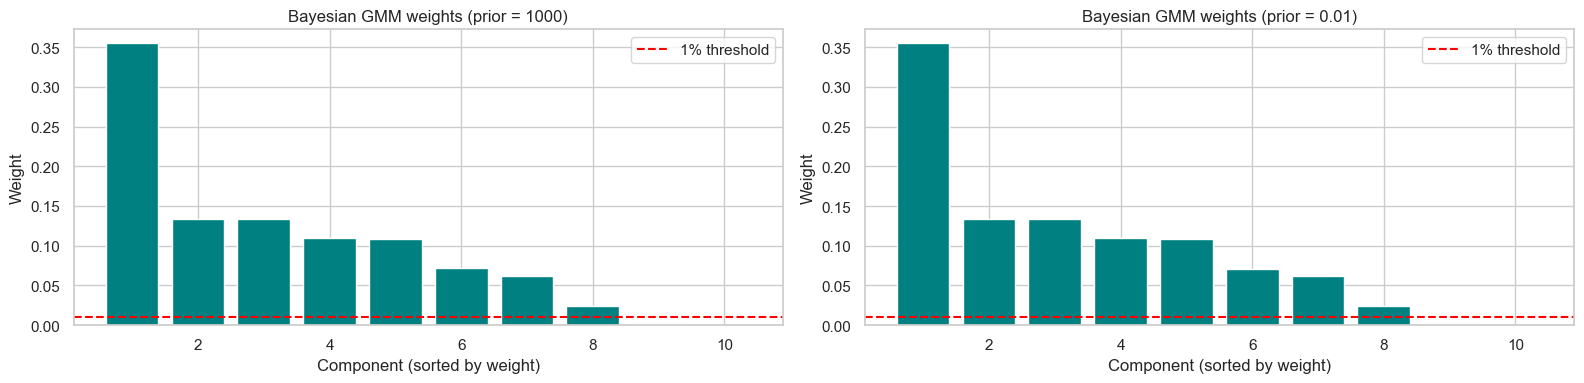

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
for ax, prior in zip(axes, [1000, 0.01]):
    w = np.sort(bgm_results[prior].weights_)[::-1]
    ax.bar(range(1, 11), w, color="teal")
    ax.axhline(0.01, color="red", linestyle="--", label="1% threshold")
    ax.set_title(f"Bayesian GMM weights (prior = {prior})")
    ax.set_xlabel("Component (sorted by weight)"); ax.set_ylabel("Weight"); ax.legend()
plt.tight_layout(); plt.show()

In [23]:
bgm_low_labels = bgm_results[0.01].predict(X_pca)
print("Cluster sizes with prior = 0.01:", np.bincount(bgm_low_labels, minlength=10).tolist())

Cluster sizes with prior = 0.01: [604, 111, 0, 508, 1608, 8, 491, 308, 278, 605]


## Task 6 – Bayesian GMM for Component Selection

### How it works
A normal GMM needs the number of components chosen in advance. A Bayesian GMM adds prior beliefs about the model's parameters. In particular, it puts a Dirichlet process prior on the component weights, which pushes the weights of unnecessary components towards 0. I only need to give a maximum number of components, and the model decides how many to actually use. The weight_concentration_prior controls this: a high value spreads the weights over more components, and a low value concentrates them on fewer components.

### My results
- I started with a maximum of 10 components and tried a very high prior (1000) and a very low prior (0.01).
- In both cases the model converged and kept 8 active components (weights above 1%). The two smallest components were switched off, with weights of 0.002 and 0.000, and the low-prior model assigned only 8 and 0 clients to them.
- The active component weights were 0.35, 0.13, 0.13, 0.11, 0.11, 0.07, 0.06 and 0.02, so one large segment holds about a third of the clients and the others are smaller.
- The Bayesian GMM chose about 8 components by itself, which is close to the local BIC minimum of 7 components from Task 5. Two different methods point to a similar number of groups.
- The prior value did not change the result. This is because the dataset is large (4,521 clients), so the evidence from the data is much stronger than the prior belief. The groups of clients with identical category values also strongly decide where the components go. In the lesson's example, the prior made a difference (5 vs 4 active components) because the dataset was much smaller.

### Role in component selection
The Bayesian GMM is useful because I do not have to test many models and compare AIC and BIC. I can set a generous maximum, and the model automatically switches off the components it does not need. The prior also makes the model more stable, because components cannot collapse as easily.

### Real-world example
A bank wants to segment its customers for marketing, but does not know how many customer types it has. Instead of guessing k, the analyst fits a Bayesian GMM with a maximum of, say, 15 components. The model keeps only the components the data supports (for example, 8 segments) and gives each customer a probability for each segment. As new customers join every month, the model can be refitted, and new segments can appear or disappear automatically without the team re-choosing k each time. Other examples include grouping products by sales patterns, finding natural groups of patients by test results, or identifying different types of network traffic for security monitoring.

## 8. Conclusion
In this assignment I applied two soft clustering methods to 4,521 bank clients after preprocessing the data and reducing it to 8 PCA components (83.3% of the variance).

- Fuzzy C-means, which I implemented myself, worked best with 5 clusters (normalized PC 0.396, silhouette 0.200). It found the same five behaviour and financial segments as K-means in Assignment 2: young new prospects, older settled savers, heavily chased clients, past-campaign contacts and financially stretched borrowers. Its memberships were quite fuzzy, with 37.5% of clients having a highest membership below 0.6, which shows that many clients sit between segments.
- The GMM with 5 components found mostly demographic segments based on job, marital status and education, and it was very confident (only 1.5% of clients below 0.6). On this mostly categorical data, the full-covariance Gaussians fitted tightly around groups of clients with identical category values, which made the probabilities overconfident.
- Both models found past-campaign contacts as a clear, separate segment that subscribed at about 22%, twice the overall rate. Neither clustering matched the yes/no subscription label (ARI close to 0).
- FCM had better cluster separation (silhouette 0.200 vs 0.095) and more realistic memberships for this overlapping data, while the GMM was more flexible because it also learns cluster sizes and shapes.
- AIC and BIC preferred full covariance but kept decreasing up to 12 components, with a local minimum at 7. This happened because the GMM's Gaussian assumption does not fit mostly categorical data well, so AIC and BIC were not reliable here.
- The Bayesian GMM automatically kept 8 of 10 components, close to the BIC local minimum, and the prior had no effect because the dataset is large.

Overall, soft clustering adds useful information that hard clustering hides: it shows which clients clearly belong to one segment and which ones are mixed, so a bank can target focused offers to clear segment members and combined offers to in-between clients.